In [1]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
import warnings
warnings.filterwarnings('ignore')

Data Understanding

In [2]:
df=sns.load_dataset('iris')
df.head(10)

,sepal_length,sepal_width,petal_length,petal_width,species
0,5.1,3.5,1.4,0.2,setosa
1,4.9,3.0,1.4,0.2,setosa
2,4.7,3.2,1.3,0.2,setosa
3,4.6,3.1,1.5,0.2,setosa
4,5.0,3.6,1.4,0.2,setosa
5,5.4,3.9,1.7,0.4,setosa
6,4.6,3.4,1.4,0.3,setosa
7,5.0,3.4,1.5,0.2,setosa
8,4.4,2.9,1.4,0.2,setosa
9,4.9,3.1,1.5,0.1,setosa


In [3]:
df.sample(10)

,sepal_length,sepal_width,petal_length,petal_width,species
111,6.4,2.7,5.3,1.9,virginica
57,4.9,2.4,3.3,1.0,versicolor
145,6.7,3.0,5.2,2.3,virginica
139,6.9,3.1,5.4,2.1,virginica
113,5.7,2.5,5.0,2.0,virginica
49,5.0,3.3,1.4,0.2,setosa
100,6.3,3.3,6.0,2.5,virginica
85,6.0,3.4,4.5,1.6,versicolor
149,5.9,3.0,5.1,1.8,virginica
78,6.0,2.9,4.5,1.5,versicolor


In [4]:
df.shape

(150, 5)

In [5]:
df.columns

Index(['sepal_length', 'sepal_width', 'petal_length', 'petal_width',
       'species'],
      dtype='str')

In [6]:
X=df.drop(columns='species')
y=df['species']

In [7]:
df.dtypes

sepal_length    float64
sepal_width     float64
petal_length    float64
petal_width     float64
species             str
dtype: object

In [8]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 150 entries, 0 to 149
Data columns (total 5 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   sepal_length  150 non-null    float64
 1   sepal_width   150 non-null    float64
 2   petal_length  150 non-null    float64
 3   petal_width   150 non-null    float64
 4   species       150 non-null    str    
dtypes: float64(4), str(1)
memory usage: 7.2 KB


Data Quality Inspection

In [9]:
df.isnull().sum()

sepal_length    0
sepal_width     0
petal_length    0
petal_width     0
species         0
dtype: int64

In [10]:
(df.isnull().sum()/len(df))*100

sepal_length    0.0
sepal_width     0.0
petal_length    0.0
petal_width     0.0
species         0.0
dtype: float64

In [11]:
df.drop_duplicates(inplace=True)
df.duplicated().sum()

np.int64(0)

In [12]:
df.value_counts().sum()

np.int64(149)

In [13]:
df['species'].value_counts()

species
setosa        50
versicolor    50
virginica     49
Name: count, dtype: int64

In [14]:
df['species'].nunique()

3

In [15]:
df['species'].unique()

<ArrowStringArray>
['setosa', 'versicolor', 'virginica']
Length: 3, dtype: str

In [16]:
df.describe()

,sepal_length,sepal_width,petal_length,petal_width
count,149.000000,149.000000,149.000000,149.000000
mean,5.843624,3.059732,3.748993,1.194631
std,0.830851,0.436342,1.767791,0.762622
min,4.300000,2.000000,1.000000,0.100000
25%,5.100000,2.800000,1.600000,0.300000
50%,5.800000,3.000000,4.300000,1.300000
75%,6.400000,3.300000,5.100000,1.800000
max,7.900000,4.400000,6.900000,2.500000


Descriptive Statistics

In [17]:
num_cols=df.select_dtypes(include='number')

print("Mean \n",num_cols.mean())
print()
print("Median \n",num_cols.median())
print()
print("Mode \n",num_cols.mode())
print()
print("Std \n",num_cols.std())
print()

Mean 
 sepal_length    5.843624
sepal_width     3.059732
petal_length    3.748993
petal_width     1.194631
dtype: float64

Median 
 sepal_length    5.8
sepal_width     3.0
petal_length    4.3
petal_width     1.3
dtype: float64

Mode 
    sepal_length  sepal_width  petal_length  petal_width
0           5.0          3.0           1.4          0.2
1           NaN          NaN           1.5          NaN

Std 
 sepal_length    0.830851
sepal_width     0.436342
petal_length    1.767791
petal_width     0.762622
dtype: float64



In [18]:
print("Min \n",num_cols.min())
print()
print("Max \n",num_cols.max())
print()
print("Range \n",num_cols.max()-num_cols.min())
print()

Min 
 sepal_length    4.3
sepal_width     2.0
petal_length    1.0
petal_width     0.1
dtype: float64

Max 
 sepal_length    7.9
sepal_width     4.4
petal_length    6.9
petal_width     2.5
dtype: float64

Range 
 sepal_length    3.6
sepal_width     2.4
petal_length    5.9
petal_width     2.4
dtype: float64



In [19]:
print("Q1 ",num_cols.quantile(.25))
print()
print("Q2 ",num_cols.quantile(.50))
print()
print("Q3 ",num_cols.quantile(.75))
print()

Q1  sepal_length    5.1
sepal_width     2.8
petal_length    1.6
petal_width     0.3
Name: 0.25, dtype: float64

Q2  sepal_length    5.8
sepal_width     3.0
petal_length    4.3
petal_width     1.3
Name: 0.5, dtype: float64

Q3  sepal_length    6.4
sepal_width     3.3
petal_length    5.1
petal_width     1.8
Name: 0.75, dtype: float64



In [20]:
mean=num_cols.mean()
median=num_cols.median()
diff=mean-median
print(diff)

sepal_length    0.043624
sepal_width     0.059732
petal_length   -0.551007
petal_width    -0.105369
dtype: float64


In [21]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
sepal_length,149.0,5.843624,0.830851,4.3,5.1,5.8,6.4,7.9
sepal_width,149.0,3.059732,0.436342,2.0,2.8,3.0,3.3,4.4
petal_length,149.0,3.748993,1.767791,1.0,1.6,4.3,5.1,6.9
petal_width,149.0,1.194631,0.762622,0.1,0.3,1.3,1.8,2.5


Univariate Analysis

In [22]:
df.groupby('species').size()

species
setosa        50
versicolor    50
virginica     49
dtype: int64

In [23]:
df['species'].value_counts()/len(df)

species
setosa        0.335570
versicolor    0.335570
virginica     0.328859
Name: count, dtype: float64

In [24]:
num_cols.mean().idxmin()

'petal_width'

In [25]:
num_cols.std().idxmax()

'petal_length'

In [26]:
q1=num_cols.quantile(.25)
q3=num_cols.quantile(.75)

iqr=q3-q1

outliers=(num_cols<(q1-1.5*iqr)) | (num_cols> (q3+1.5*iqr))
outliers.sum()

sepal_length    0
sepal_width     4
petal_length    0
petal_width     0
dtype: int64

In [27]:
range=num_cols.max()-num_cols.min()
range.idxmax()

'petal_length'

Visualization

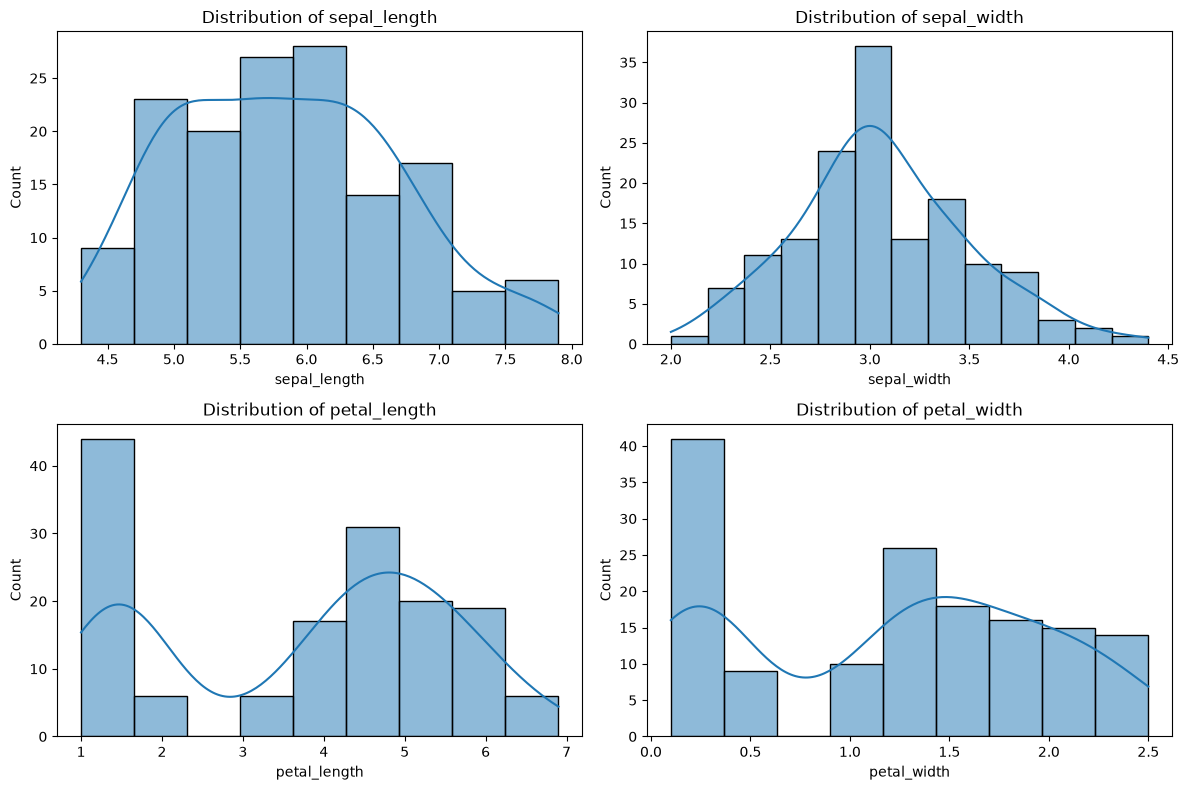

In [34]:
fig,ax=plt.subplots(2,2,figsize=(12,8))
ax=ax.flatten()

for i,col in enumerate(num_cols.columns):
    sns.histplot(data=num_cols,x=col,ax=ax[i],kde=True)
    ax[i].set_title(f'Distribution of {col}')

plt.tight_layout()
plt.show()

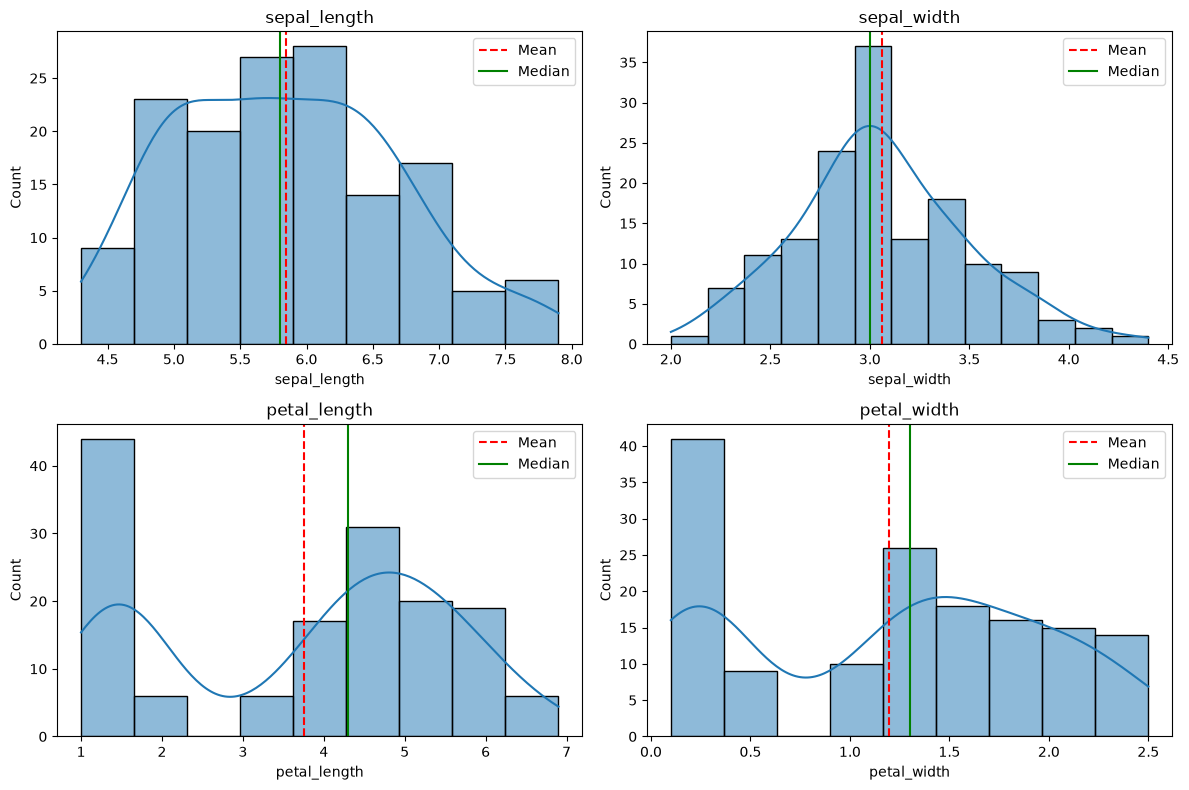

In [38]:
fig,ax =plt.subplots(2,2,figsize=(12,8))
ax=ax.flatten()

for i,col in enumerate(num_cols.columns):
    sns.histplot(data=num_cols,x=col,kde=True,ax=ax[i])

    mean=num_cols[col].mean()
    median=num_cols[col].median()

    ax[i].axvline(mean,linestyle="--",color="red",label="Mean")
    ax[i].axvline(median,linestyle="-",color="green",label="Median")

    ax[i].set_title(col)
    ax[i].legend()

plt.tight_layout()
plt.show()

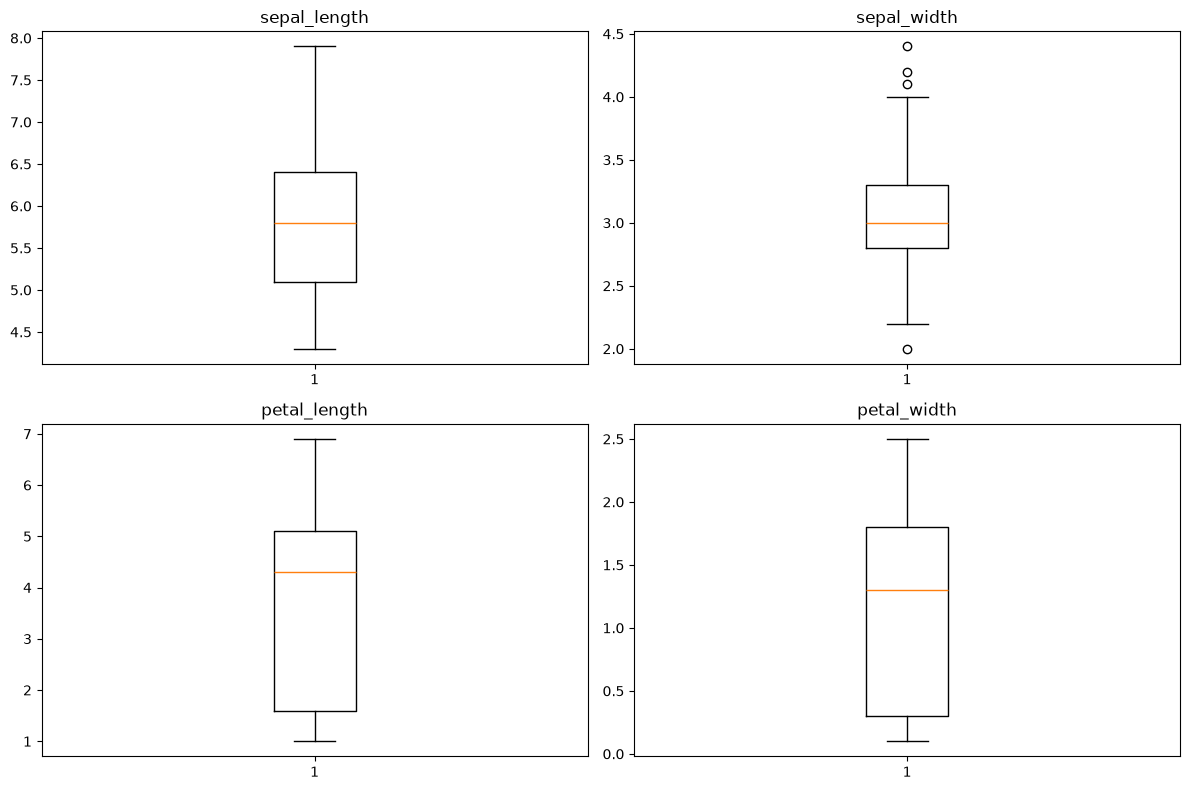

In [42]:
fig, ax=plt.subplots(2,2,figsize=(12,8))
ax=ax.flatten()
for i,col in enumerate(num_cols.columns):
    ax[i].boxplot(data=df,x=col)

    ax[i].set_title(col)

plt.tight_layout()
plt.show()

In [43]:
num_cols.skew()

sepal_length    0.312826
sepal_width     0.307149
petal_length   -0.263101
petal_width    -0.090076
dtype: float64

In [45]:
df.groupby('species').mean()

,sepal_length,sepal_width,petal_length,petal_width
species,,,,
setosa,5.006000,3.428000,1.462000,0.246000
versicolor,5.936000,2.770000,4.260000,1.326000
virginica,6.604082,2.979592,5.561224,2.028571


In [46]:
df.groupby('species').median()

,sepal_length,sepal_width,petal_length,petal_width
species,,,,
setosa,5.0,3.4,1.50,0.2
versicolor,5.9,2.8,4.35,1.3
virginica,6.5,3.0,5.60,2.0


In [47]:
df.groupby('species')['sepal_length'].mean().idxmax()

'virginica'

In [49]:
range=df.groupby('species')[num_cols.columns].max()-df.groupby('species')[num_cols.columns].min()
range

,sepal_length,sepal_width,petal_length,petal_width
species,,,,
setosa,1.5,2.1,0.9,0.5
versicolor,2.1,1.4,2.1,0.8
virginica,3.0,1.6,2.4,1.1


In [50]:
df['sepal_length'].corr(df['sepal_width'])

np.float64(-0.11812926214116401)

<Axes: xlabel='sepal_length', ylabel='sepal_width'>

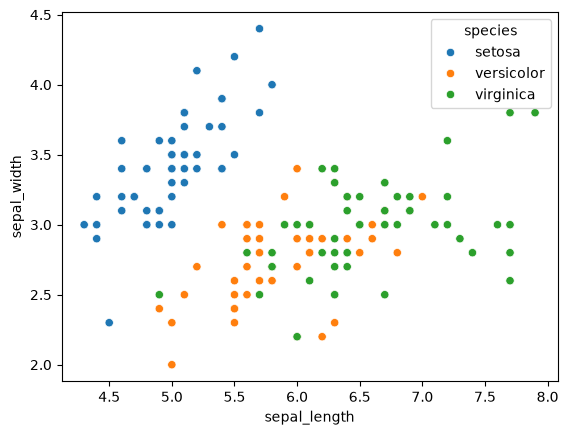

In [53]:
sns.scatterplot(data=df,x='sepal_length',y='sepal_width',hue='species')

<Axes: xlabel='petal_length', ylabel='petal_width'>

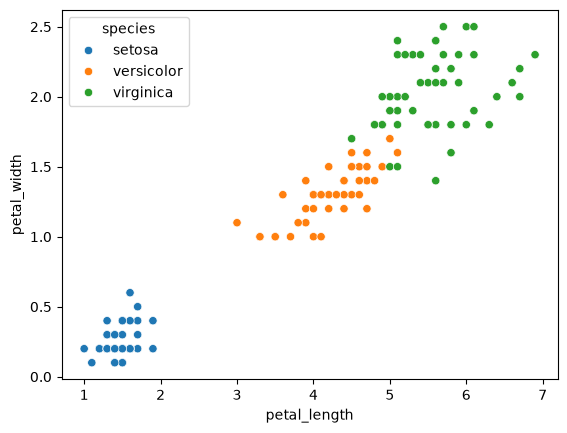

In [55]:
sns.scatterplot(x=df['petal_length'],y=df['petal_width'],hue='species',data=df)

In [56]:
df['petal_length'].corr(df['petal_width'])

np.float64(0.9627722945997867)

In [57]:
correlation=num_cols.corr(method='pearson')
correlation

,sepal_length,sepal_width,petal_length,petal_width
sepal_length,1.000000,-0.118129,0.873738,0.820620
sepal_width,-0.118129,1.000000,-0.426028,-0.362894
petal_length,0.873738,-0.426028,1.000000,0.962772
petal_width,0.820620,-0.362894,0.962772,1.000000


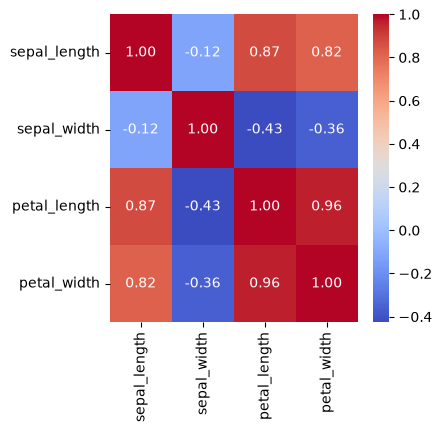

In [60]:
plt.figure(figsize=(4,4))
sns.heatmap(correlation,annot=True,fmt='.2f',cmap='coolwarm')
plt.show()

In [61]:
df.groupby('species').apply(
    lambda x: x['petal_length'].corr(x['petal_width'])
)

species
setosa        0.331630
versicolor    0.786668
virginica     0.317198
dtype: float64

Advance Visualization

In [63]:
def plot_feature(feature,plot_type='box'):
    if plot_type=='box':
        sns.boxplot(data=df,x='species',y=feature)
    elif plot_type=='violin':
        sns.violinplot(data=df,x='species',y=feature)
    elif(plot_type=='hist'):
        sns.histplot(data=df,x=feature,hue='species',kde=True)
    else:
        print("Invalid Plot Type")
        return
    plt.title(f"{plot_type} Plot of {feature}")
    plt.tight_layout()
    plt.show()

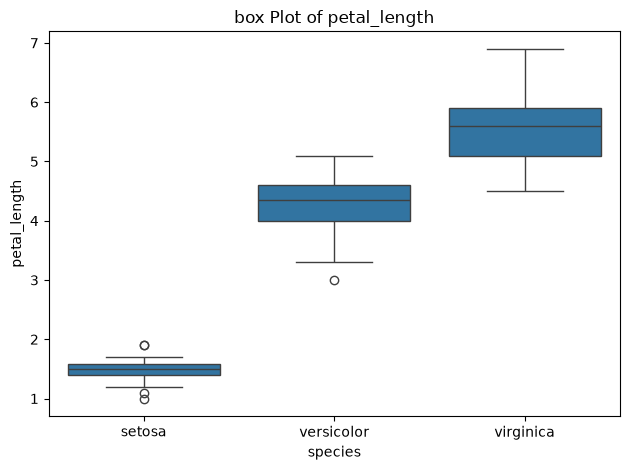

In [66]:
plot_feature('petal_length')

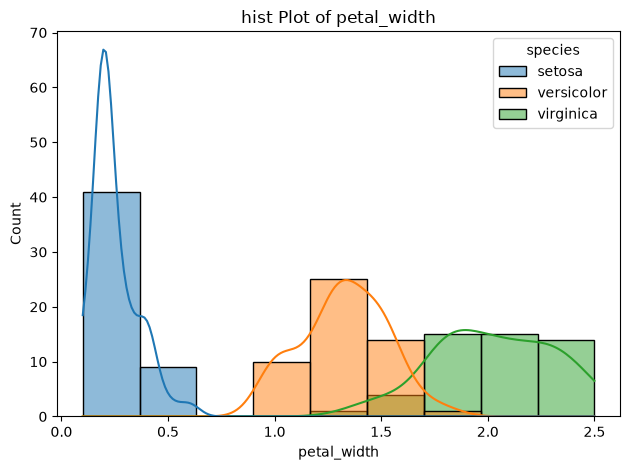

In [67]:
plot_feature('petal_width',"hist")

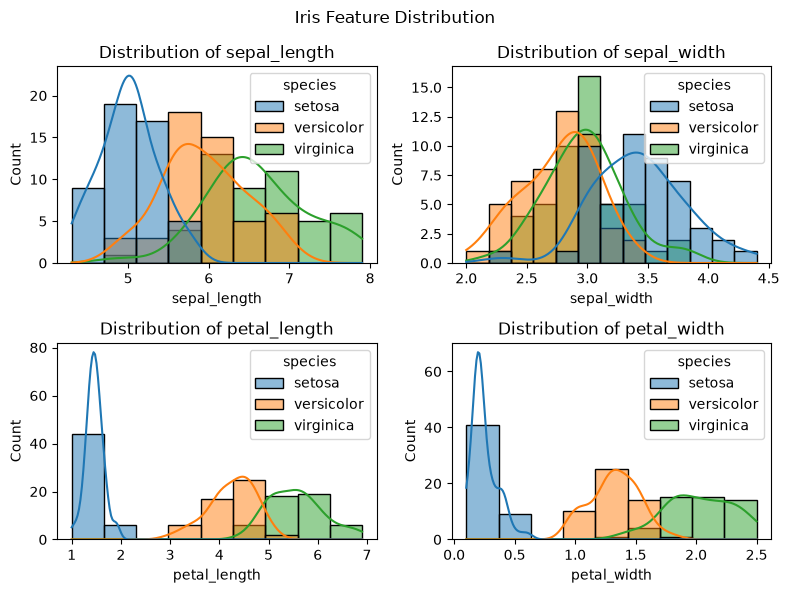

In [69]:
fig,ax=plt.subplots(2,2,figsize=(8,6))
ax=ax.flatten()

for i,col in enumerate(num_cols.columns):
    sns.histplot(data=df,x=col,hue='species',kde=True,ax=ax[i])
    ax[i].set_title(f"Distribution of {col}")

plt.suptitle("Iris Feature Distribution",fontsize=12)
plt.tight_layout()
plt.show()

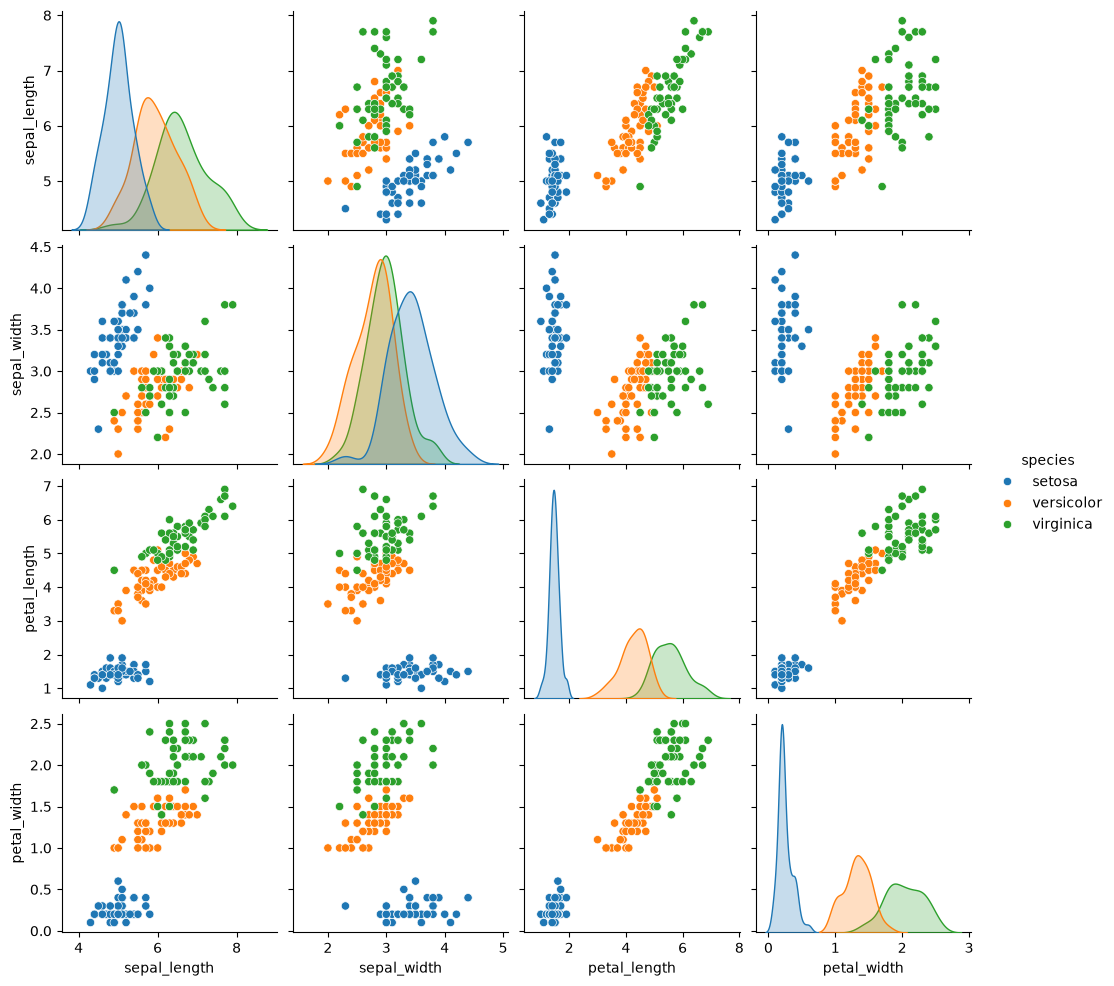

In [73]:
sns.pairplot(data=df,hue='species',diag_kind='auto',height=2.5)
plt.show()

1. Petal length and petal width provide the clearest
   separation between Iris species.

2. Petal length and petal width show a strong positive
   relationship.

3. Versicolor and Virginica overlap more than Setosa
   and the other species.

4. Setosa forms a relatively distinct cluster.

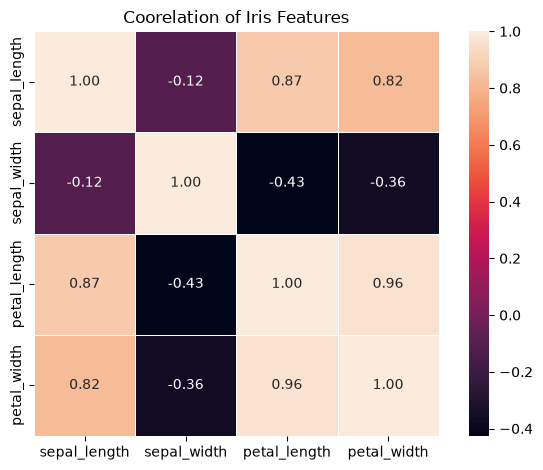

In [75]:
sns.heatmap(correlation,annot=True,fmt='.2f',linewidth=0.5,square=True)
plt.title("Coorelation of Iris Features")
plt.tight_layout()
plt.show()

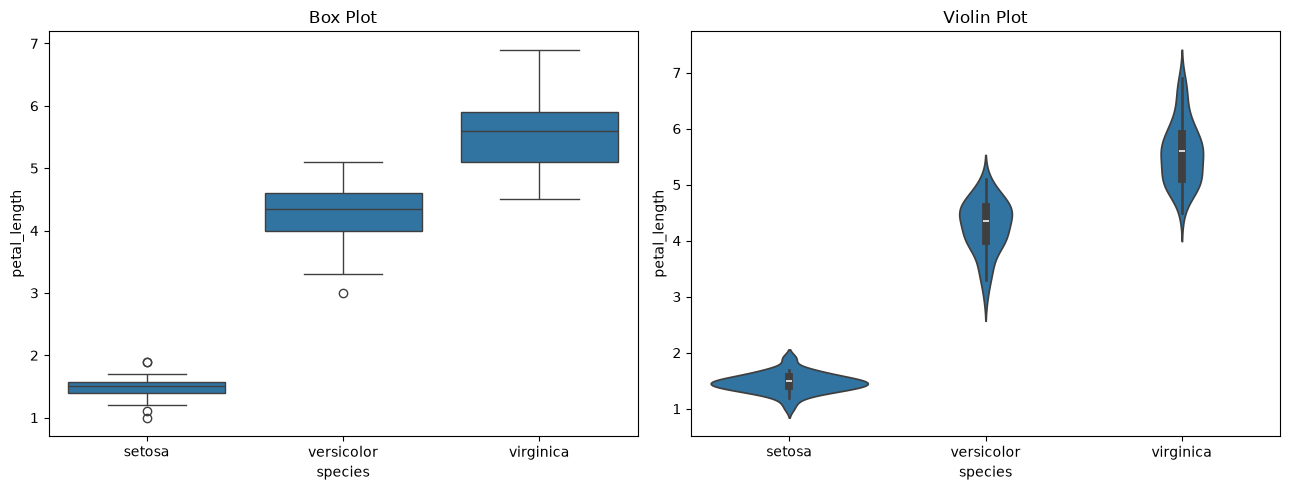

In [76]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

sns.boxplot(data=df, x='species', y='petal_length', ax=axes[0])
axes[0].set_title('Box Plot')

sns.violinplot(data=df, x='species', y='petal_length', ax=axes[1])
axes[1].set_title('Violin Plot')

plt.tight_layout()
plt.show()

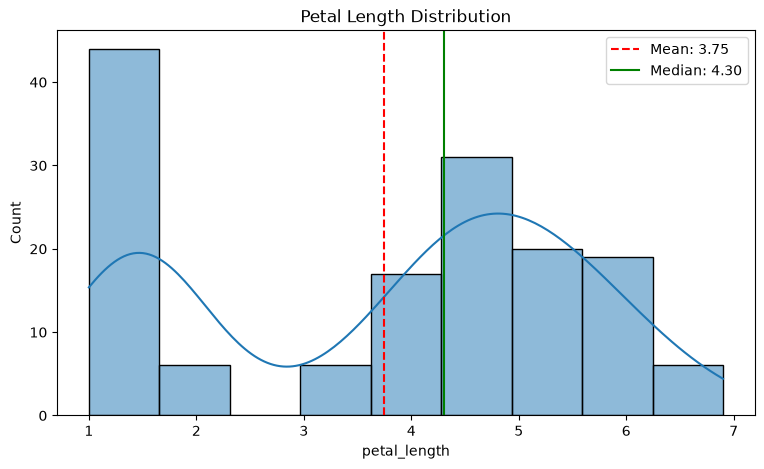

In [77]:
plt.figure(figsize=(9, 5))

sns.histplot(data=df, x='petal_length', kde=True)

mean = df['petal_length'].mean()
median = df['petal_length'].median()

plt.axvline(mean, color='red', linestyle='--', label=f'Mean: {mean:.2f}')
plt.axvline(median, color='green', linestyle='-', label=f'Median: {median:.2f}')

plt.title('Petal Length Distribution')
plt.legend()
plt.show()